In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import statsmodels.formula.api as smf

In [3]:
from scipy import stats

In [4]:
import seaborn as sns
import math

In [5]:

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [6]:
from sklearn.model_selection import train_test_split

In [7]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [8]:
!pip install pysus

In [9]:
import pysus

PySUS 2.12.3 -- welcome!
Data cache: /root/pysus
Change it with: pysus.set_cache('/your/path')
Browse datasets with: pysus.info()



In [10]:
file_bag = pysus.ftp.sih(state="RN", year=2024, month=[1])


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

RJRN2401.parquet: 0.00B [00:00, ?B/s]

ERRN2401.parquet: 0.00B [00:00, ?B/s]


RDRN2401.parquet: 0.00B [00:00, ?B/s]


RDRN2401.parquet:   0%|          | 0.00/964k [00:00<?, ?B/s]


RDRN2401.parquet:   7%|▋         | 65.5k/964k [00:00<00:00, 7.21MB/s]

ERRN2401.parquet:   0%|          | 0.00/66.5k [00:00<?, ?B/s]

ERRN2401.parquet:  99%|█████████▊| 65.5k/66.5k [00:00<00:00, 8.06MB/s]
RJRN2401.parquet:   0%|          | 0.00/171k [00:00<?, ?B/s]
RJRN2401.parquet:  38%|███▊      | 65.5k/171k [00:00<00:00, 7.89MB/s]

ERRN2401.parquet: 100%|██████████| 66.5k/66.5k [00:00<00:00, 388kB/s] 



RDRN2401.parquet:  14%|█▎        | 131k/964k [00:00<00:01, 634kB/s]  
RJRN2401.parquet:  77%|███████▋  | 131k/171k [00:00<00:00, 741kB/s]  


RDRN2401.parquet:  20%|██        | 197k/964k [00:00<00:00, 885kB/s]
RJRN2401.parquet: 100%|██████████| 171k/171k [00:00<00:00, 543kB/s]



RDRN2401.parquet:  27%|██▋       | 262k/964k [00:00<00:00, 714kB/s]


RDRN2401.parquet:  34%|███▍      | 328k/964k [00:00<00:0

In [11]:
df = file_bag.to_dataframe()

In [12]:
df_final = df

In [13]:

print("arquivos:")
for i, file_obj in enumerate(file_bag):
    print(f"{i}: {file_obj.name}")

arquivos:
0: SPRN2401.parquet
1: ERRN2401.parquet
2: RJRN2401.parquet
3: RDRN2401.parquet


In [14]:

selected_file_object = file_bag[3]
file_path = selected_file_object.path
df_single_file = pd.read_parquet(file_path)

print(f"carregando arquivo: {selected_file_object.name}")

display(df_single_file.head())

carregando arquivo: RDRN2401.parquet


,UF_ZI,ANO_CMPT,MES_CMPT,ESPEC,CGC_HOSP,N_AIH,IDENT,CEP,MUNIC_RES,NASC,...,DIAGSEC9,TPDISEC1,TPDISEC2,TPDISEC3,TPDISEC4,TPDISEC5,TPDISEC6,TPDISEC7,TPDISEC8,TPDISEC9
0,240000,2024,01,02,08241754013638,2424104046254,1,59380000,240310,19930208,...,,0,0,0,0,0,0,0,0,0
1,240000,2024,01,02,08241754013638,2424104046265,1,59380000,240310,20060621,...,,0,0,0,0,0,0,0,0,0
2,240000,2024,01,03,08241754010450,2423103973653,1,59865000,241450,19870216,...,,0,0,0,0,0,0,0,0,0
3,240000,2024,01,03,08241754010450,2423103973686,1,59504000,240990,19500115,...,,0,0,0,0,0,0,0,0,0
4,240000,2024,01,03,08241754010450,2423103973741,1,59650000,240020,19980601,...,,0,0,0,0,0,0,0,0,0


In [15]:
df = df_single_file

In [16]:
df_final = df[["IDADE","SEXO","RACA_COR","DIAG_PRINC","CAR_INT","PROC_REA","MUNIC_RES","MUNIC_MOV","COMPLEX","GESTAO",'MORTE']]

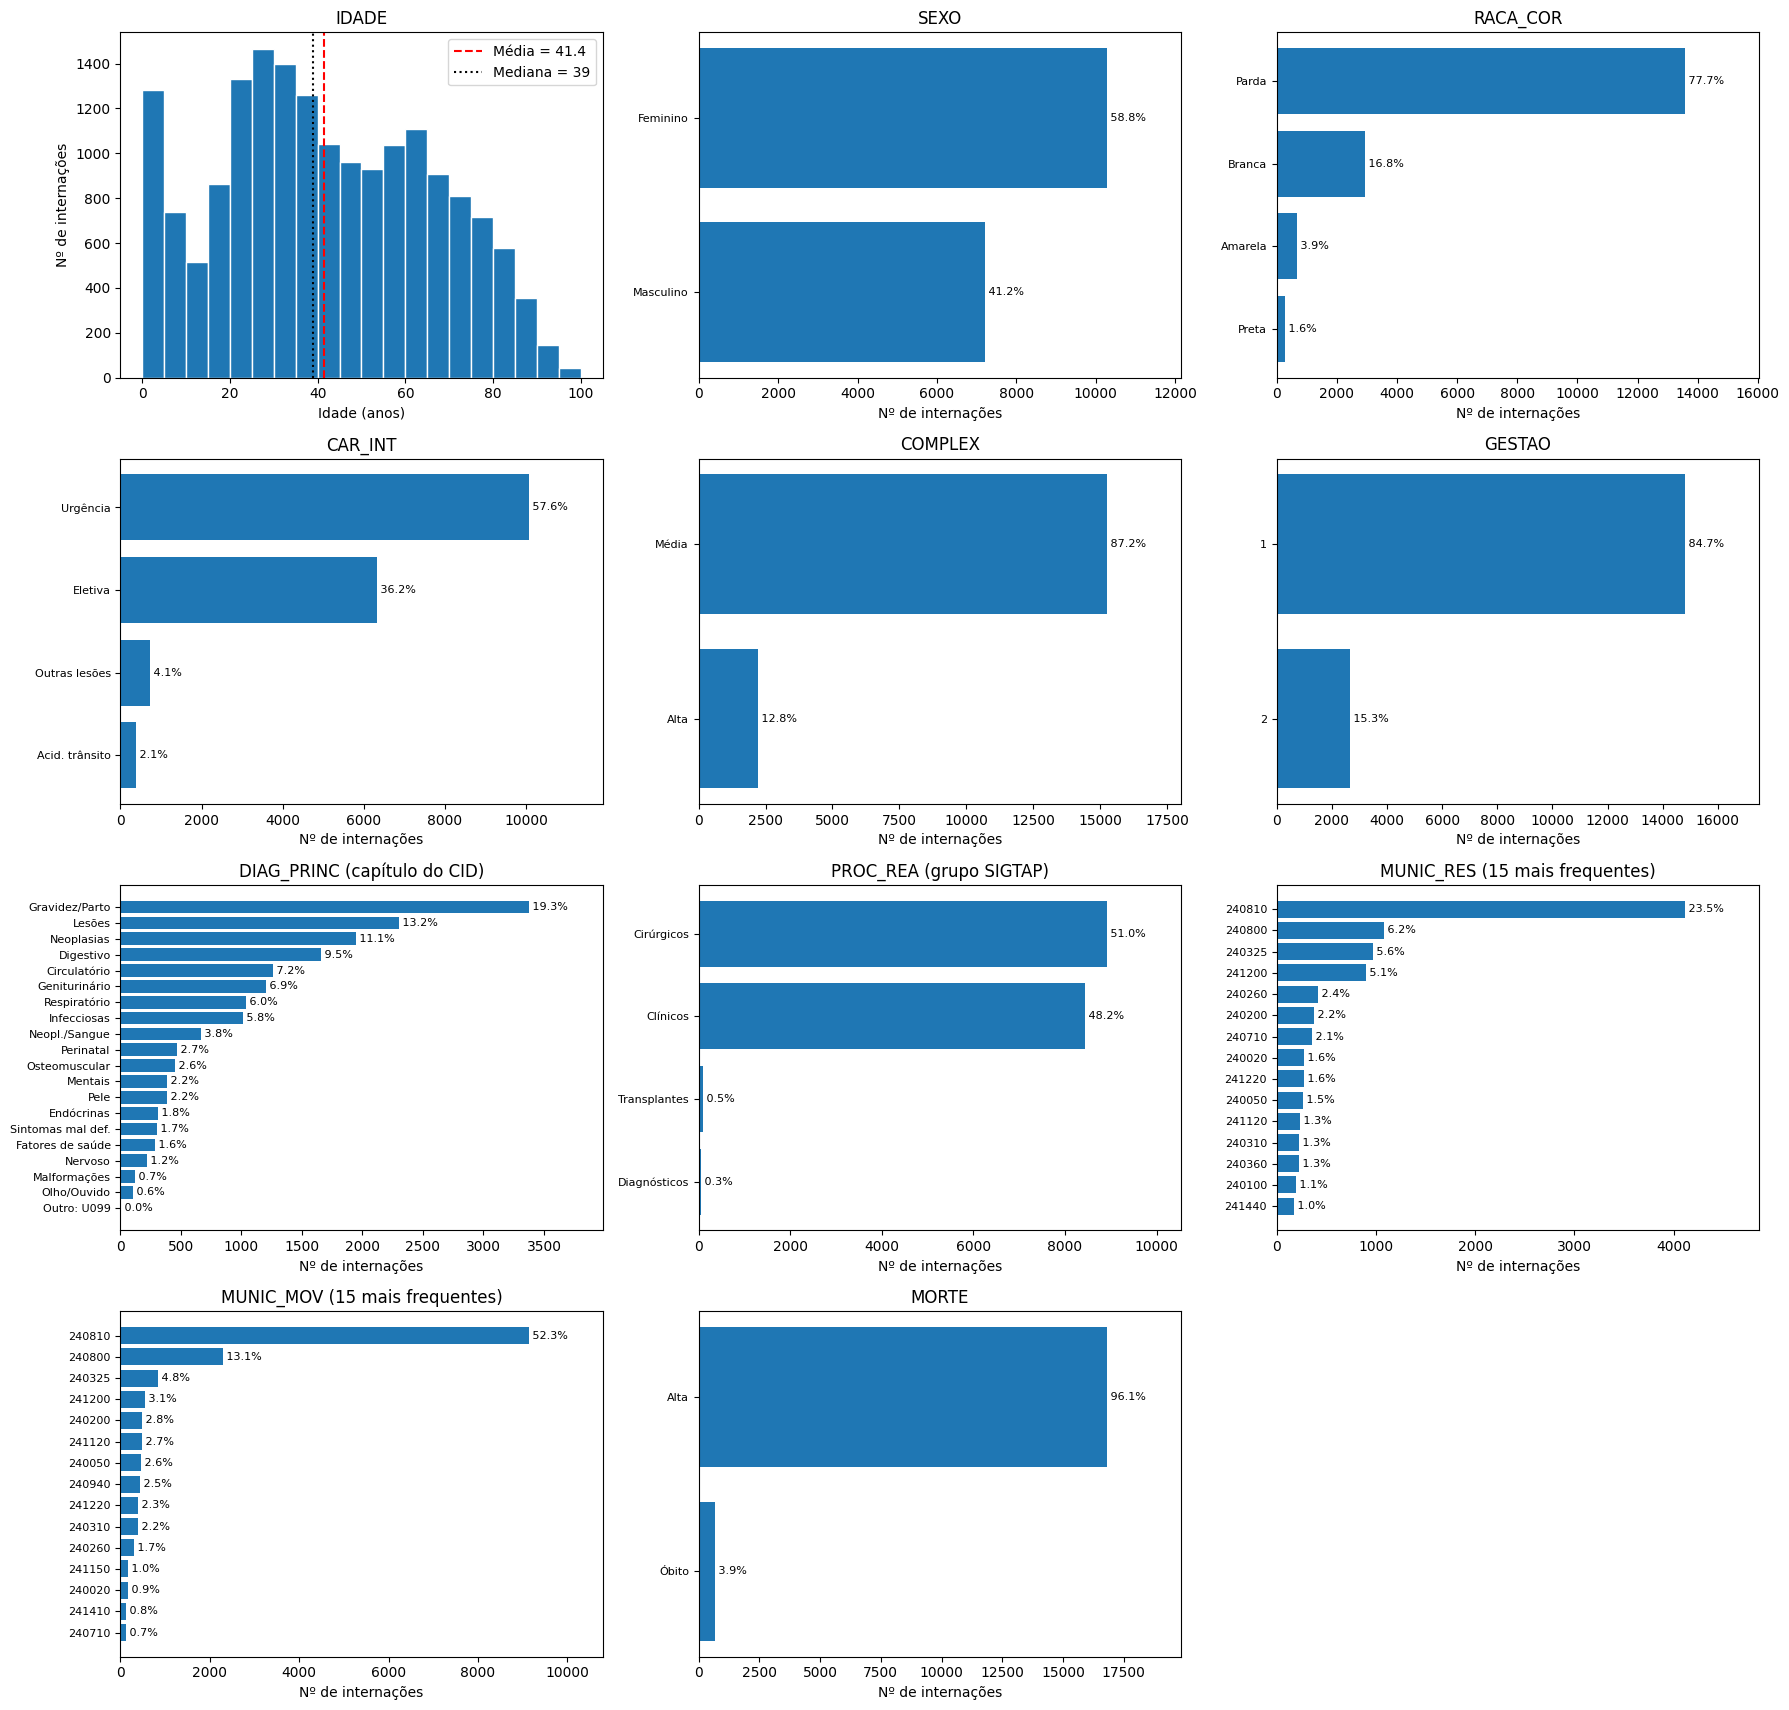

N = 17493
count    17493.00
mean        41.39
std         24.08
min          0.00
25%         23.00
50%         39.00
75%         61.00
max         99.00
Name: IDADE, dtype: float64


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

d = df_final.copy()

def cod(s, n=None):
    """Padroniza códigos como texto (tira espaços e '.0'; completa com zeros à esquerda)."""
    s = s.astype("string").str.strip().str.replace(r"\.0$", "", regex=True)
    return s.str.zfill(n) if n else s

# ---------- Rótulos dos códigos do SIH (confira no dicionário do DATASUS) ----------
rot_sexo  = {"1": "Masculino", "3": "Feminino", "2": "Feminino", "0": "Ignorado"}
rot_raca  = {"01": "Branca", "02": "Preta", "03": "Parda", "04": "Amarela",
             "05": "Indígena", "99": "Sem informação"}
rot_car   = {"01": "Eletiva", "02": "Urgência", "03": "Acid. trabalho",
             "04": "Acid. trajeto", "05": "Acid. trânsito", "06": "Outras lesões"}
rot_comp  = {"01": "Atenção básica", "02": "Média", "03": "Alta"}
rot_proc  = {"02": "Diagnósticos", "03": "Clínicos", "04": "Cirúrgicos", "05": "Transplantes"}
rot_morte = {"0": "Alta", "1": "Óbito"}
cap_cid = {"A": "Infecciosas", "B": "Infecciosas", "C": "Neoplasias", "D": "Neopl./Sangue",
           "E": "Endócrinas", "F": "Mentais", "G": "Nervoso", "H": "Olho/Ouvido",
           "I": "Circulatório", "J": "Respiratório", "K": "Digestivo", "L": "Pele",
           "M": "Osteomuscular", "N": "Geniturinário", "O": "Gravidez/Parto",
           "P": "Perinatal", "Q": "Malformações", "R": "Sintomas mal def.",
           "S": "Lesões", "T": "Lesões", "Z": "Fatores de saúde"}

categoricas = {
    "SEXO":       cod(d["SEXO"]).map(rot_sexo),
    "RACA_COR":   cod(d["RACA_COR"], 2).map(rot_raca),
    "CAR_INT":    cod(d["CAR_INT"], 2).map(rot_car),
    "COMPLEX":    cod(d["COMPLEX"], 2).map(rot_comp),
    "GESTAO":     cod(d["GESTAO"]),
    "DIAG_PRINC (capítulo do CID)": cod(d["DIAG_PRINC"]).str.upper().str[0].map(cap_cid),
    "PROC_REA (grupo SIGTAP)":      cod(d["PROC_REA"], 10).str[:2].map(rot_proc),
    "MUNIC_RES (15 mais frequentes)": cod(d["MUNIC_RES"]),
    "MUNIC_MOV (15 mais frequentes)": cod(d["MUNIC_MOV"]),
    "MORTE":      cod(d["MORTE"]).map(rot_morte),
}
# Se algum código não estiver no mapa, mostra o código original em vez de vazio
originais = {"SEXO": "SEXO", "RACA_COR": "RACA_COR", "CAR_INT": "CAR_INT", "COMPLEX": "COMPLEX",
             "DIAG_PRINC (capítulo do CID)": "DIAG_PRINC", "PROC_REA (grupo SIGTAP)": "PROC_REA",
             "MORTE": "MORTE"}
for nome, col in originais.items():
    categoricas[nome] = categoricas[nome].fillna("Outro: " + cod(d[col]).fillna("NA"))

# ---------- Figura ----------
n = 1 + len(categoricas)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4.3 * nrows))
axes = axes.ravel()

# 1) Histograma da idade
idade = pd.to_numeric(d["IDADE"], errors="coerce")
ax = axes[0]
ax.hist(idade.dropna(), bins=range(0, int(idade.max()) + 6, 5), color="tab:blue", edgecolor="white")
ax.axvline(idade.mean(), color="red", ls="--", label=f"Média = {idade.mean():.1f}")
ax.axvline(idade.median(), color="black", ls=":", label=f"Mediana = {idade.median():.0f}")
ax.set(title="IDADE", xlabel="Idade (anos)", ylabel="Nº de internações")
ax.legend()

# 2) Barras para as categóricas
for ax, (nome, s) in zip(axes[1:], categoricas.items()):
    cont = s.value_counts(dropna=False)
    if "15 mais" in nome:
        cont = cont.head(15)
    cont = cont.sort_values()
    ax.barh(cont.index.astype(str), cont.values, color="tab:blue")
    total = len(s)
    for i, v in enumerate(cont.values):
        ax.text(v, i, f" {100 * v / total:.1f}%", va="center", fontsize=8)
    ax.set(title=nome, xlabel="Nº de internações")
    ax.set_xlim(0, cont.max() * 1.18)
    ax.tick_params(axis="y", labelsize=8)

for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
fig.savefig("distribuicao_variaveis.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"N = {len(d)}")
print(idade.describe().round(2))

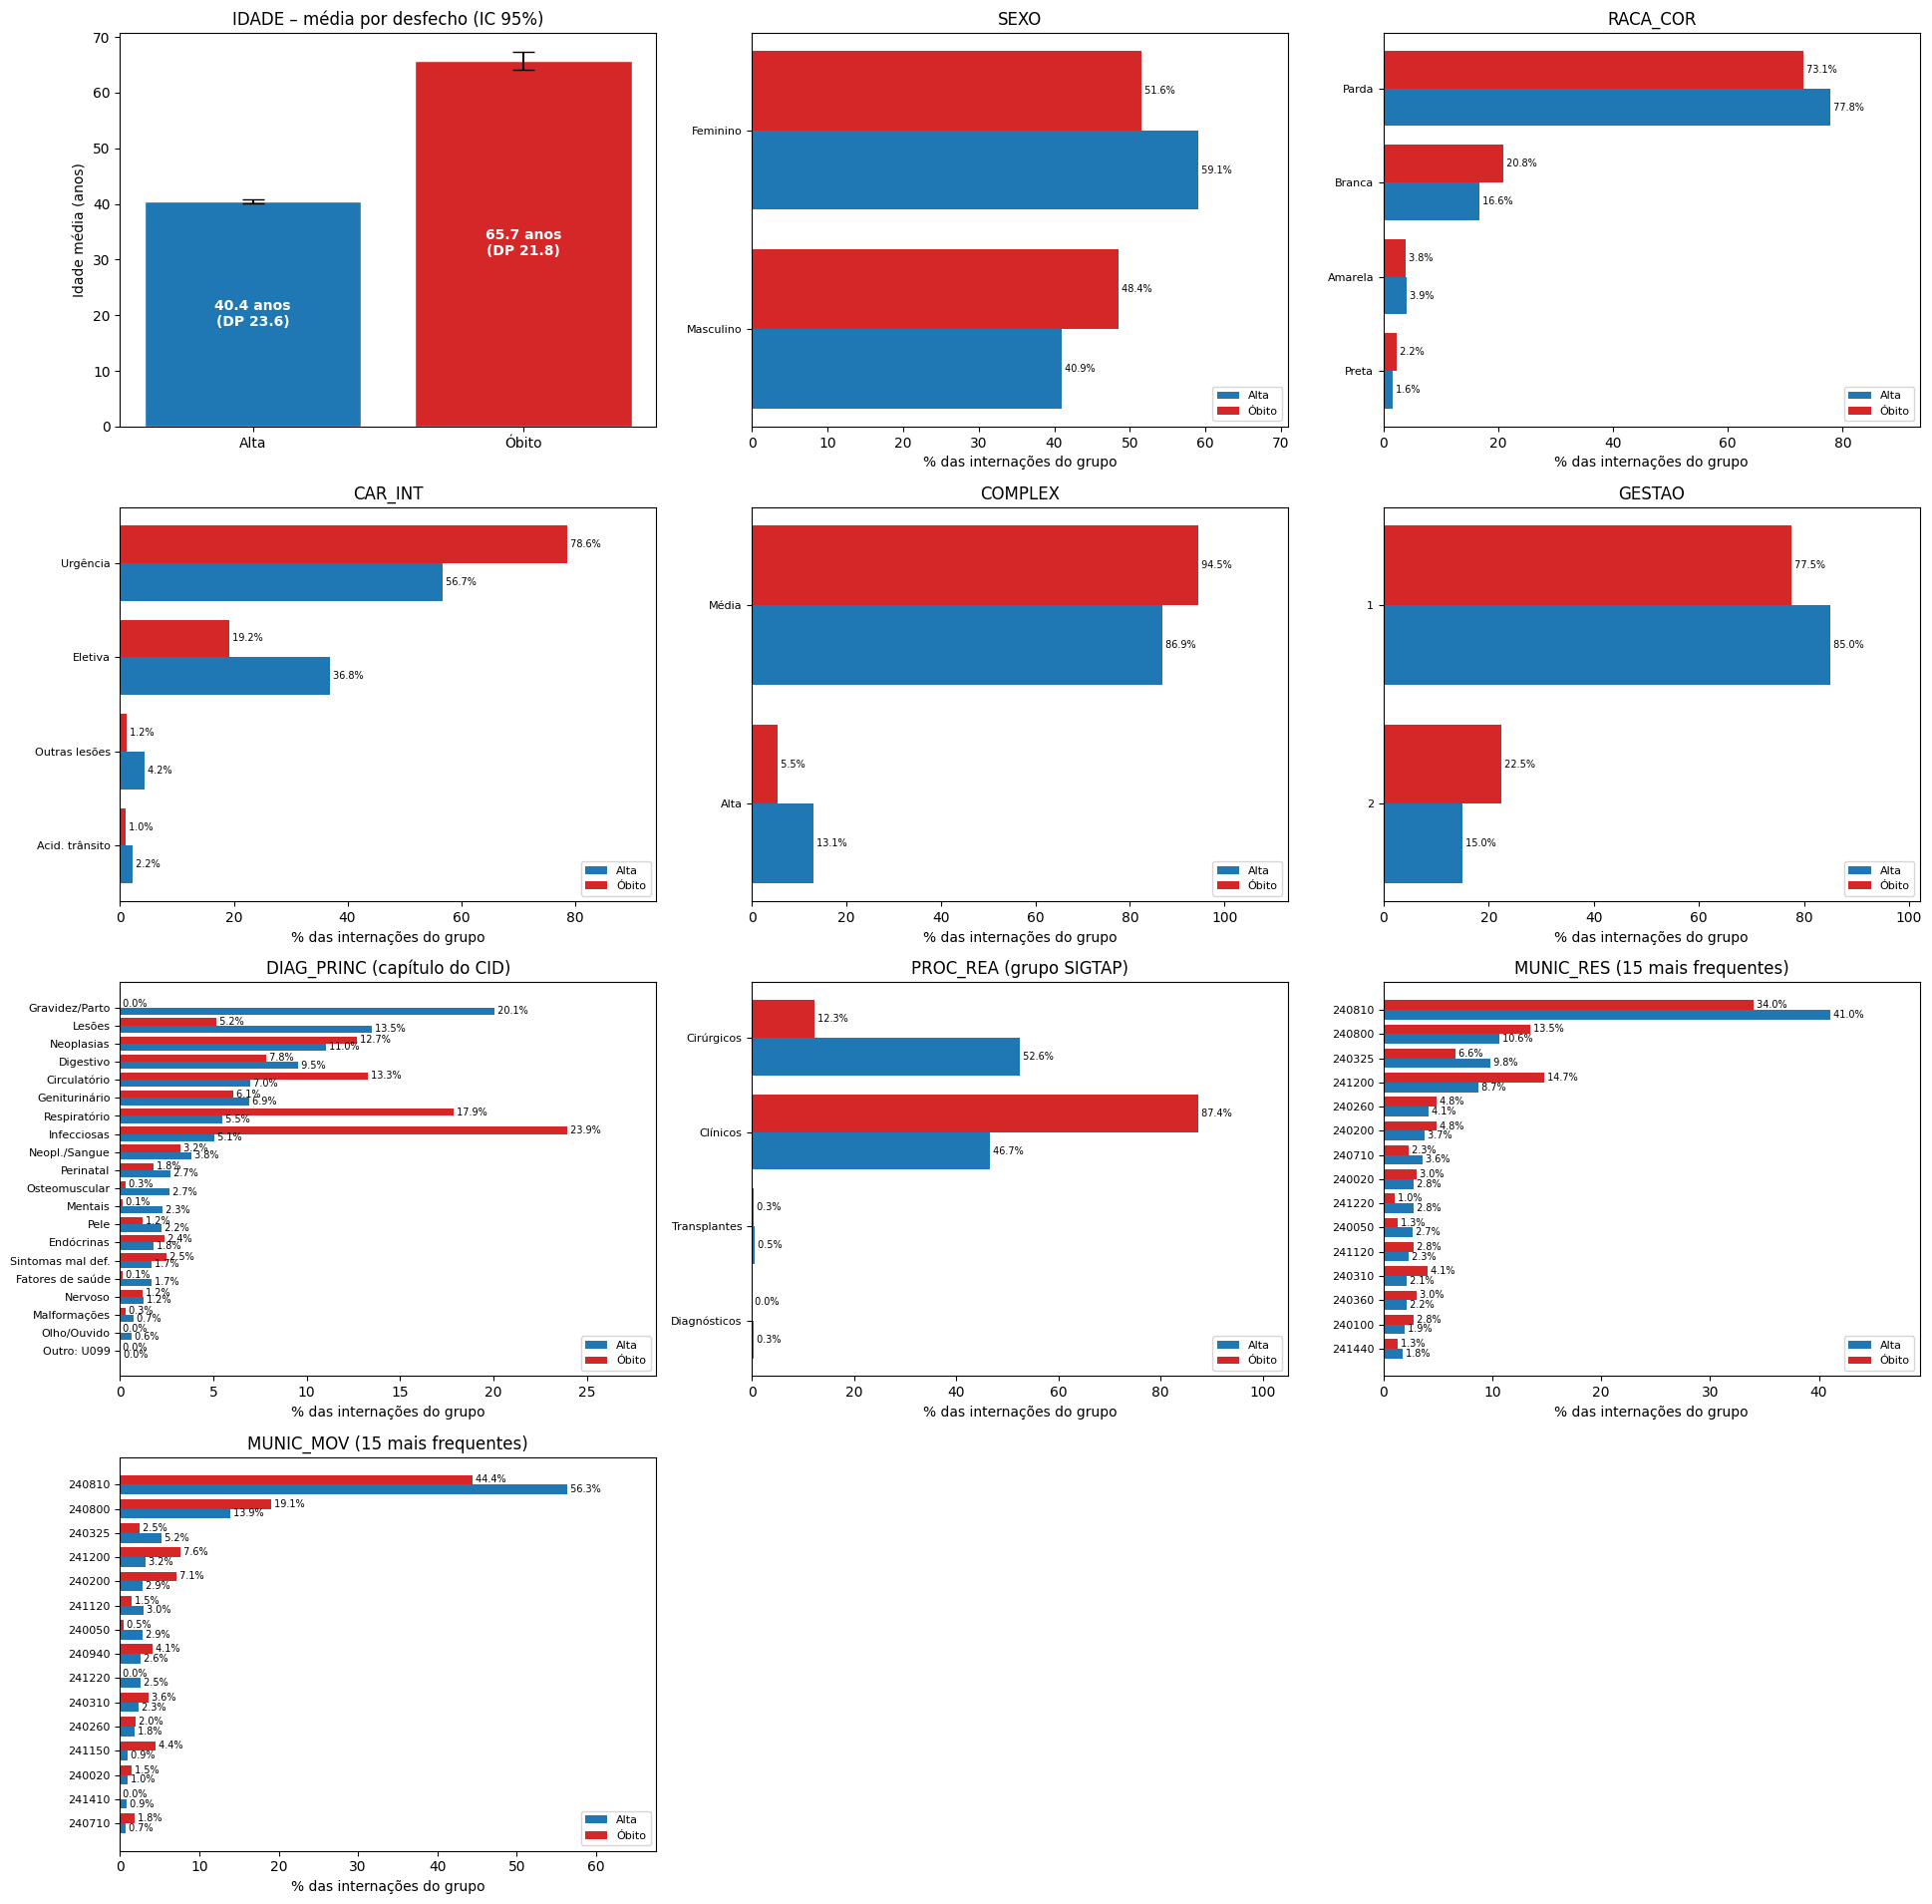

        mean    std  count
MORTE                     
Alta   40.41  23.64  16816
Óbito  65.75  21.81    677


In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MODO = "percentual"     # "percentual" = % dentro de cada desfecho | "contagem" = nº de internações

desfecho = categoricas["MORTE"]            # "Alta" / "Óbito"
grupos = ["Alta", "Óbito"]
cores = {"Alta": "tab:blue", "Óbito": "tab:red"}

vars_cat = {k: v for k, v in categoricas.items() if k != "MORTE"}
n = 1 + len(vars_cat)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(6.5 * ncols, 4.8 * nrows))
axes = axes.ravel()

# ---------- 1) IDADE: média por desfecho (com IC 95%) ----------
idade = pd.to_numeric(d["IDADE"], errors="coerce")
resumo = idade.groupby(desfecho).agg(["mean", "std", "count"]).reindex(grupos)
ic = 1.96 * resumo["std"] / np.sqrt(resumo["count"])

ax = axes[0]
barras = ax.bar(grupos, resumo["mean"], yerr=ic, capsize=8,
                color=[cores[g] for g in grupos], edgecolor="white")
for b, m, s in zip(barras, resumo["mean"], resumo["std"]):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() / 2,
            f"{m:.1f} anos\n(DP {s:.1f})", ha="center", va="center", color="white", fontweight="bold")
ax.set(title="IDADE – média por desfecho (IC 95%)", ylabel="Idade média (anos)")

# ---------- 2) Categóricas com MORTE como hue ----------
for ax, (nome, s) in zip(axes[1:], vars_cat.items()):
    tab = pd.crosstab(s, desfecho).reindex(columns=grupos, fill_value=0)
    if "15 mais" in nome:
        tab = tab.loc[tab.sum(axis=1).nlargest(15).index]
    tab = tab.loc[tab.sum(axis=1).sort_values().index]

    if MODO == "percentual":
        valores = 100 * tab / tab.sum(axis=0)          # % dentro de cada desfecho
        xlabel = "% das internações do grupo"
    else:
        valores = tab
        xlabel = "Nº de internações"

    y = np.arange(len(valores))
    h = 0.4
    for j, g in enumerate(grupos):
        pos = y + (j - 0.5) * h
        ax.barh(pos, valores[g], height=h, color=cores[g], label=g)
        for p, v in zip(pos, valores[g]):
            txt = f" {v:.1f}%" if MODO == "percentual" else f" {int(v)}"
            ax.text(v, p, txt, va="center", fontsize=7)

    ax.set_yticks(y, valores.index.astype(str), fontsize=8)
    ax.set(title=nome, xlabel=xlabel)
    ax.set_xlim(0, valores.values.max() * 1.2)
    ax.legend(fontsize=8, loc="lower right")

for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
fig.savefig("distribuicao_por_desfecho.png", dpi=200, bbox_inches="tight")
plt.show()

# Tabela de apoio: idade por desfecho
print(resumo.round(2))

In [19]:
df_final.head()

,IDADE,SEXO,RACA_COR,DIAG_PRINC,CAR_INT,PROC_REA,MUNIC_RES,MUNIC_MOV,COMPLEX,GESTAO,MORTE
0,30,3,03,O820,01,0411010042,240310,240310,02,2,0
1,17,3,03,O458,02,0411010034,240310,240310,02,2,0
2,36,1,03,I602,02,0303040149,241450,240800,02,2,0
3,73,3,01,I64,02,0303040149,240990,240800,02,2,0
4,25,3,04,K800,02,0303070129,240020,240800,02,2,0


In [20]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17493 entries, 0 to 17492
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   IDADE       17493 non-null  object
 1   SEXO        17493 non-null  object
 2   RACA_COR    17493 non-null  object
 3   DIAG_PRINC  17493 non-null  object
 4   CAR_INT     17493 non-null  object
 5   PROC_REA    17493 non-null  object
 6   MUNIC_RES   17493 non-null  object
 7   MUNIC_MOV   17493 non-null  object
 8   COMPLEX     17493 non-null  object
 9   GESTAO      17493 non-null  object
 10  MORTE       17493 non-null  object
dtypes: object(11)
memory usage: 1.5+ MB


In [21]:

def cod_municipio(s):

    s = (s.astype("string")
          .str.strip()
          .str.replace(r"\.0$", "", regex=True)
          .str.replace(r"\D", "", regex=True))
    s = s.str[:6]
    return s.where(s.str.len() == 6)

res = cod_municipio(df_final["MUNIC_RES"])
mov = cod_municipio(df_final["MUNIC_MOV"])

df_final["mesmo_municipio"] = np.where(res.isna() | mov.isna(), np.nan,
                                       (res == mov).astype(float))


df_final["MORTE"] = pd.to_numeric(df_final["MORTE"], errors="coerce")


print(df_final["mesmo_municipio"].value_counts(dropna=False))
print("\nTaxa de óbito por grupo:")
print(df_final.groupby("mesmo_municipio")["MORTE"].agg(["count", "sum", "mean"]).round(4))

mesmo_municipio
0.0    9360
1.0    8133
Name: count, dtype: int64

Taxa de óbito por grupo:
                 count  sum    mean
mesmo_municipio                    
0.0               9360  319  0.0341
1.0               8133  358  0.0440


/tmp/ipykernel_795/22365467.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final["mesmo_municipio"] = np.where(res.isna() | mov.isna(), np.nan,
/tmp/ipykernel_795/22365467.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final["MORTE"] = pd.to_numeric(df_final["MORTE"], errors="coerce")


In [22]:



MIN_OBITOS = 15
REF_CID = None


d = df_final.copy()

def texto(s):
    return (s.astype("string").str.strip().str.upper()
             .str.replace(r"\.0$", "", regex=True))

def resumo(col):
    t = d.groupby(col, dropna=False)["MORTE"].agg(n="count", obitos="sum", taxa="mean")
    t["taxa"] = (100 * t["taxa"]).round(2)
    print(f"\n--- {col} ---")
    print(t.sort_values("obitos", ascending=False))
    poucos = t.index[t["obitos"] < 5].tolist()
    if poucos:
        print(f"ATENÇÃO: categorias com < 5 óbitos (risco de separação): {poucos}")


car = texto(d["CAR_INT"]).str.zfill(2)
mapa_car = {"01": "eletiva", "02": "urgencia",
            "03": "acidente", "04": "acidente", "05": "acidente", "06": "acidente"}
d["carater"] = car.map(mapa_car)

d["urgencia"] = np.where(d["carater"].isna(), np.nan,
                         d["carater"].isin(["urgencia", "acidente"]).astype(float))
resumo("carater")


cid = texto(d["DIAG_PRINC"]).str.replace(r"[^A-Z0-9]", "", regex=True).str[:3]

def capitulo(c):
    if pd.isna(c) or len(c) < 3:
        return np.nan
    l, n = c[0], int(c[1:3]) if c[1:3].isdigit() else -1
    if l in "AB":                       return "infecciosas"
    if l == "C" or (l == "D" and n <= 48): return "neoplasias"
    if l == "D":                        return "sangue_imunidade"
    if l == "E":                        return "endocrinas"
    if l == "F":                        return "mentais"
    if l == "G":                        return "nervoso"
    if l == "H":                        return "olho_ouvido"
    if l == "I":                        return "circulatorio"
    if l == "J":                        return "respiratorio"
    if l == "K":                        return "digestivo"
    if l in "LM":                       return "pele_osteomuscular"
    if l == "N":                        return "geniturinario"
    if l == "O":                        return "gravidez_parto"
    if l == "P":                        return "perinatal"
    if l == "Q":                        return "malformacoes"
    if l == "R":                        return "sintomas_mal_definidos"
    if l in "STVWXY":                   return "lesoes_causas_externas"
    return "outros"

d["cid_cap"] = cid.map(capitulo)


obitos_cap = d.groupby("cid_cap")["MORTE"].sum()
raros = obitos_cap[obitos_cap < MIN_OBITOS].index
d["grupo_cid"] = d["cid_cap"].where(~d["cid_cap"].isin(raros), "outros")
print(f"\nCapítulos agrupados em 'outros' (< {MIN_OBITOS} óbitos): {list(raros)}")
resumo("grupo_cid")


proc = texto(d["PROC_REA"]).str.replace(r"\D", "", regex=True).str.zfill(10)
grupo_proc = proc.str[:2]

d["cirurgico"] = np.where(d["PROC_REA"].isna(), np.nan,
                          grupo_proc.isin(["04", "05"]).astype(float))
resumo("cirurgico")


if REF_CID is None:
    REF_CID = d.groupby("grupo_cid")["MORTE"].sum().idxmax()
print(f"\nCategoria de referência do CID: {REF_CID}")

dummies_cid = pd.get_dummies(d["grupo_cid"], prefix="cid", dtype=float)
dummies_cid = dummies_cid.drop(columns=f"cid_{REF_CID}")
dummies_cid[d["grupo_cid"].isna()] = np.nan
d = pd.concat([d, dummies_cid], axis=1)

novas_features = ["urgencia", "cirurgico"] + dummies_cid.columns.tolist()
print("\nNovas variáveis para o modelo:", novas_features)
print(f"Total de parâmetros acrescentados: {len(novas_features)}")

df_final = d


--- carater ---
              n  obitos  taxa
carater                      
urgencia  10073     532  5.28
eletiva    6326     130  2.06
acidente   1094      15  1.37

Capítulos agrupados em 'outros' (< 15 óbitos): ['gravidez_parto', 'malformacoes', 'mentais', 'nervoso', 'olho_ouvido', 'outros', 'pele_osteomuscular', 'perinatal', 'sangue_imunidade']

--- grupo_cid ---
                           n  obitos   taxa
grupo_cid                                  
infecciosas             1013     162  15.99
respiratorio            1041     121  11.62
neoplasias              2468      95   3.85
circulatorio            1260      90   7.14
digestivo               1654      53   3.20
outros                  5934      47   0.79
geniturinario           1203      41   3.41
lesoes_causas_externas  2303      35   1.52
sintomas_mal_definidos   303      17   5.61
endocrinas               314      16   5.10

--- cirurgico ---
              n  obitos  taxa
cirurgico                    
0.0        8487     59

In [23]:
df_final

,IDADE,SEXO,RACA_COR,DIAG_PRINC,CAR_INT,PROC_REA,MUNIC_RES,MUNIC_MOV,COMPLEX,GESTAO,...,cirurgico,cid_circulatorio,cid_digestivo,cid_endocrinas,cid_geniturinario,cid_lesoes_causas_externas,cid_neoplasias,cid_outros,cid_respiratorio,cid_sintomas_mal_definidos
0,30,3,03,O820,01,0411010042,240310,240310,02,2,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,17,3,03,O458,02,0411010034,240310,240310,02,2,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,36,1,03,I602,02,0303040149,241450,240800,02,2,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,73,3,01,I64,02,0303040149,240990,240800,02,2,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,25,3,04,K800,02,0303070129,240020,240800,02,2,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17488,42,3,03,N390,01,0305020013,241460,241460,02,1,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
17489,50,1,03,E105,01,0303030038,241460,241460,02,1,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
17490,82,3,01,E871,01,0303030046,241460,241460,02,1,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
17491,2,1,03,K122,01,0303080078,241460,241460,02,1,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [24]:
s = df_final["SEXO"].astype(str).str.strip()

df_final = df_final[s.isin(["1", "3"])].copy()
df_final["masculino"] = (df_final["SEXO"].astype(str).str.strip() == "1").astype(int)

print(df_final["masculino"].value_counts())

masculino
0    10284
1     7209
Name: count, dtype: int64


In [25]:
df_final = df_final.drop('SEXO',axis=1)

In [26]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17493 entries, 0 to 17492
Data columns (total 26 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   IDADE                       17493 non-null  object 
 1   RACA_COR                    17493 non-null  object 
 2   DIAG_PRINC                  17493 non-null  object 
 3   CAR_INT                     17493 non-null  object 
 4   PROC_REA                    17493 non-null  object 
 5   MUNIC_RES                   17493 non-null  object 
 6   MUNIC_MOV                   17493 non-null  object 
 7   COMPLEX                     17493 non-null  object 
 8   GESTAO                      17493 non-null  object 
 9   MORTE                       17493 non-null  int64  
 10  mesmo_municipio             17493 non-null  float64
 11  carater                     17493 non-null  object 
 12  urgencia                    17493 non-null  float64
 13  cid_cap                     174

In [27]:
d = df_final.copy()


for c in ["COMPLEX", "GESTAO", "RACA_COR"]:
    print(c, d[c].astype("string").str.strip().value_counts(dropna=False).to_dict())


comp = d["COMPLEX"].astype("string").str.strip().str.zfill(2)
d["alta_complex"] = comp.map({"02": 0.0, "03": 1.0})


gest = d["GESTAO"].astype("string").str.strip()
d["gestao_estadual"] = gest.map({"E": 1.0, "M": 0.0, "1": 1.0, "2": 0.0})


raca = d["RACA_COR"].astype("string").str.strip().str.zfill(2)
grupo_raca = raca.map({"01": "branca", "02": "negra", "03": "negra",
                       "04": "outras", "05": "outras", "99": "sem_info"}).fillna("sem_info")
d = pd.concat([d, pd.get_dummies(grupo_raca, prefix="raca", dtype=float)
                    .drop(columns="raca_branca")], axis=1)
print(pd.crosstab(grupo_raca, d["MORTE"], margins=True))

df_final = d


features = (["IDADE", "masculino", "urgencia", "cirurgico", "mesmo_municipio",
             "alta_complex", "gestao_estadual"]
            + [c for c in df_final.columns if c.startswith("cid_") and c != "cid_cap"]
            + [c for c in df_final.columns if c.startswith("raca_")])
print(f"{len(features)} parâmetros:", features)

COMPLEX {'02': 15260, '03': 2233}
GESTAO {'1': 14820, '2': 2673}
RACA_COR {'03': 13586, '01': 2936, '04': 688, '02': 283}
MORTE         0    1    All
RACA_COR                   
branca     2795  141   2936
negra     13359  510  13869
outras      662   26    688
All       16816  677  17493
18 parâmetros: ['IDADE', 'masculino', 'urgencia', 'cirurgico', 'mesmo_municipio', 'alta_complex', 'gestao_estadual', 'cid_circulatorio', 'cid_digestivo', 'cid_endocrinas', 'cid_geniturinario', 'cid_lesoes_causas_externas', 'cid_neoplasias', 'cid_outros', 'cid_respiratorio', 'cid_sintomas_mal_definidos', 'raca_negra', 'raca_outras']


In [28]:
features

['IDADE',
 'masculino',
 'urgencia',
 'cirurgico',
 'mesmo_municipio',
 'alta_complex',
 'gestao_estadual',
 'cid_circulatorio',
 'cid_digestivo',
 'cid_endocrinas',
 'cid_geniturinario',
 'cid_lesoes_causas_externas',
 'cid_neoplasias',
 'cid_outros',
 'cid_respiratorio',
 'cid_sintomas_mal_definidos',
 'raca_negra',
 'raca_outras']

In [29]:
df_final.head()

,IDADE,RACA_COR,DIAG_PRINC,CAR_INT,PROC_REA,MUNIC_RES,MUNIC_MOV,COMPLEX,GESTAO,MORTE,...,cid_lesoes_causas_externas,cid_neoplasias,cid_outros,cid_respiratorio,cid_sintomas_mal_definidos,masculino,alta_complex,gestao_estadual,raca_negra,raca_outras
0,30,03,O820,01,0411010042,240310,240310,02,2,0,...,0.0,0.0,1.0,0.0,0.0,0,0.0,0.0,1.0,0.0
1,17,03,O458,02,0411010034,240310,240310,02,2,0,...,0.0,0.0,1.0,0.0,0.0,0,0.0,0.0,1.0,0.0
2,36,03,I602,02,0303040149,241450,240800,02,2,0,...,0.0,0.0,0.0,0.0,0.0,1,0.0,0.0,1.0,0.0
3,73,01,I64,02,0303040149,240990,240800,02,2,0,...,0.0,0.0,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0
4,25,04,K800,02,0303070129,240020,240800,02,2,0,...,0.0,0.0,0.0,0.0,0.0,0,0.0,0.0,0.0,1.0


In [30]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17493 entries, 0 to 17492
Data columns (total 30 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   IDADE                       17493 non-null  object 
 1   RACA_COR                    17493 non-null  object 
 2   DIAG_PRINC                  17493 non-null  object 
 3   CAR_INT                     17493 non-null  object 
 4   PROC_REA                    17493 non-null  object 
 5   MUNIC_RES                   17493 non-null  object 
 6   MUNIC_MOV                   17493 non-null  object 
 7   COMPLEX                     17493 non-null  object 
 8   GESTAO                      17493 non-null  object 
 9   MORTE                       17493 non-null  int64  
 10  mesmo_municipio             17493 non-null  float64
 11  carater                     17493 non-null  object 
 12  urgencia                    17493 non-null  float64
 13  cid_cap                     174

In [31]:
import warnings
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score

alvo = "MORTE"
features = features

K = 5

cols = features or [c for c in df_final.select_dtypes("number").columns if c != alvo]
dados = df_final[cols + [alvo]].dropna()

X, y = dados[cols].apply(pd.to_numeric, errors="coerce"), dados[alvo].astype(int)

kf = StratifiedKFold(n_splits=K, shuffle=True, random_state=42)

modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
res = cross_validate(modelo, X, y, cv=kf,
                     scoring=["accuracy", "roc_auc", "f1", "precision", "recall"],
                     return_train_score=True)

tabela = pd.DataFrame({m: res[f"test_{m}"]
                       for m in ["accuracy", "roc_auc", "f1", "precision", "recall"]},
                      index=[f"Fold {i+1}" for i in range(K)])
display(tabela.round(3))
display(tabela.agg(["mean", "std"]).round(3))
print(f"Acurácia treino: {res['train_accuracy'].mean():.3f} | teste: {res['test_accuracy'].mean():.3f}")

metricas, coefs, pvals = [], [], []

for i, (tr, te) in enumerate(kf.split(X, y), start=1):
    X_tr, X_te, y_tr, y_te = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        glm = sm.GLM(y_tr, sm.add_constant(X_tr), family=sm.families.Binomial()).fit()

    prob = glm.predict(sm.add_constant(X_te, has_constant="add"))
    pred = (prob >= 0.5).astype(int)

    metricas.append({"fold": i,
                     "accuracy": accuracy_score(y_te, pred),
                     "roc_auc": roc_auc_score(y_te, prob),
                     "f1": f1_score(y_te, pred)})
    coefs.append(glm.params.rename(f"Fold {i}"))
    pvals.append(glm.pvalues.rename(f"Fold {i}"))

met = pd.DataFrame(metricas).set_index("fold")
display(met.round(3))
display(met.agg(["mean", "std"]).round(3))

coefs = pd.concat(coefs, axis=1)
display(coefs.round(3))
display(np.exp(coefs.mean(axis=1)).rename("odds ratio médio").round(3))
display((pd.concat(pvals, axis=1) < 0.05).sum(axis=1)
        .rename(f"folds com p < 0,05 (de {K})"))

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,accuracy,roc_auc,f1,precision,recall
Fold 1,0.961,0.860,0.000,0.000,0.000
Fold 2,0.961,0.853,0.014,0.333,0.007
Fold 3,0.961,0.876,0.014,0.500,0.007
Fold 4,0.962,0.891,0.015,1.000,0.007
Fold 5,0.962,0.846,0.043,0.600,0.022


,accuracy,roc_auc,f1,precision,recall
mean,0.961,0.865,0.017,0.487,0.009
std,0.000,0.018,0.016,0.366,0.008


Acurácia treino: 0.961 | teste: 0.961


,accuracy,roc_auc,f1
fold,,,
1,0.961,0.860,0.000
2,0.961,0.853,0.014
3,0.961,0.876,0.014
4,0.962,0.891,0.015
5,0.962,0.846,0.043


,accuracy,roc_auc,f1
mean,0.961,0.865,0.017
std,0.000,0.018,0.016


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5
const,-4.166,-4.187,-3.956,-4.169,-4.216
IDADE,0.040,0.040,0.038,0.039,0.039
masculino,0.112,0.053,0.064,0.016,0.010
urgencia,0.616,0.692,0.626,0.584,0.643
cirurgico,-1.380,-1.310,-1.225,-1.357,-1.279
mesmo_municipio,-0.122,-0.233,-0.210,-0.184,-0.096
alta_complex,-0.636,-0.872,-0.563,-0.702,-0.622
gestao_estadual,-0.323,-0.259,-0.290,-0.226,-0.286
cid_circulatorio,-1.250,-1.279,-1.247,-1.114,-1.137
cid_digestivo,-1.000,-0.913,-1.004,-0.820,-1.066


,odds ratio médio
const,0.016
IDADE,1.040
masculino,1.052
urgencia,1.882
cirurgico,0.270
mesmo_municipio,0.845
alta_complex,0.507
gestao_estadual,0.758
cid_circulatorio,0.300
cid_digestivo,0.383


,"folds com p < 0,05 (de 5)"
const,5
IDADE,5
masculino,0
urgencia,5
cirurgico,5
mesmo_municipio,2
alta_complex,5
gestao_estadual,4
cid_circulatorio,5
cid_digestivo,5


In [32]:
remover = ["raca_outras","cid_sintomas_mal_definidos","masculino","mesmo_municipio"]
features = [f for f in features if f not in remover]

In [33]:
X = features
y = df_final['MORTE']

In [34]:
import warnings
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score

alvo = "MORTE"
features = features

K = 5

cols = features or [c for c in df_final.select_dtypes("number").columns if c != alvo]
dados = df_final[cols + [alvo]].dropna()

X, y = dados[cols].apply(pd.to_numeric, errors="coerce"), dados[alvo].astype(int)

kf = StratifiedKFold(n_splits=K, shuffle=True, random_state=42)

modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
res = cross_validate(modelo, X, y, cv=kf,
                     scoring=["accuracy", "roc_auc", "f1", "precision", "recall"],
                     return_train_score=True)

tabela = pd.DataFrame({m: res[f"test_{m}"]
                       for m in ["accuracy", "roc_auc", "f1", "precision", "recall"]},
                      index=[f"Fold {i+1}" for i in range(K)])
display(tabela.round(3))
display(tabela.agg(["mean", "std"]).round(3))
print(f"Acurácia treino: {res['train_accuracy'].mean():.3f} | teste: {res['test_accuracy'].mean():.3f}")

metricas, coefs, pvals = [], [], []

for i, (tr, te) in enumerate(kf.split(X, y), start=1):
    X_tr, X_te, y_tr, y_te = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        glm = sm.GLM(y_tr, sm.add_constant(X_tr), family=sm.families.Binomial()).fit()

    prob = glm.predict(sm.add_constant(X_te, has_constant="add"))
    pred = (prob >= 0.5).astype(int)

    metricas.append({"fold": i,
                     "accuracy": accuracy_score(y_te, pred),
                     "roc_auc": roc_auc_score(y_te, prob),
                     "f1": f1_score(y_te, pred)})
    coefs.append(glm.params.rename(f"Fold {i}"))
    pvals.append(glm.pvalues.rename(f"Fold {i}"))

met = pd.DataFrame(metricas).set_index("fold")
display(met.round(3))
display(met.agg(["mean", "std"]).round(3))

coefs = pd.concat(coefs, axis=1)
display(coefs.round(3))
display(np.exp(coefs.mean(axis=1)).rename("odds ratio médio").round(3))
display((pd.concat(pvals, axis=1) < 0.05).sum(axis=1)
        .rename(f"folds com p < 0,05 (de {K})"))

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,accuracy,roc_auc,f1,precision,recall
Fold 1,0.961,0.858,0.000,0.0,0.000
Fold 2,0.961,0.853,0.000,0.0,0.000
Fold 3,0.961,0.877,0.000,0.0,0.000
Fold 4,0.962,0.889,0.015,1.0,0.007
Fold 5,0.962,0.847,0.043,1.0,0.022


,accuracy,roc_auc,f1,precision,recall
mean,0.961,0.865,0.012,0.400,0.006
std,0.001,0.018,0.019,0.548,0.010


Acurácia treino: 0.961 | teste: 0.961


,accuracy,roc_auc,f1
fold,,,
1,0.961,0.859,0.000
2,0.961,0.853,0.000
3,0.961,0.877,0.000
4,0.962,0.889,0.015
5,0.962,0.847,0.043


,accuracy,roc_auc,f1
mean,0.961,0.865,0.012
std,0.001,0.018,0.019


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5
const,-4.212,-4.235,-4.064,-4.270,-4.351
IDADE,0.040,0.040,0.038,0.038,0.039
urgencia,0.596,0.656,0.598,0.560,0.624
cirurgico,-1.421,-1.339,-1.263,-1.379,-1.319
alta_complex,-0.602,-0.829,-0.525,-0.666,-0.601
gestao_estadual,-0.344,-0.318,-0.326,-0.266,-0.290
cid_circulatorio,-1.179,-1.205,-1.159,-1.044,-1.064
cid_digestivo,-0.926,-0.854,-0.917,-0.759,-0.988
cid_endocrinas,-1.527,-1.646,-1.305,-1.349,-1.260
cid_geniturinario,-1.203,-1.297,-1.149,-0.912,-1.140


,odds ratio médio
const,0.015
IDADE,1.040
urgencia,1.835
cirurgico,0.261
alta_complex,0.525
gestao_estadual,0.734
cid_circulatorio,0.323
cid_digestivo,0.411
cid_endocrinas,0.242
cid_geniturinario,0.320


,"folds com p < 0,05 (de 5)"
const,5
IDADE,5
urgencia,5
cirurgico,5
alta_complex,5
gestao_estadual,5
cid_circulatorio,5
cid_digestivo,5
cid_endocrinas,5
cid_geniturinario,5


--- Métricas por fold ---
      limiar  AUC treino  AUC teste  AP treino  AP teste  LogLoss treino  LogLoss teste  Brier treino  Brier teste  Precisão  Recall      F1
fold                                                                                                                                        
1     0.1724      0.8694     0.8586     0.2357    0.2161          0.1235         0.1266        0.0325       0.0331    0.2647  0.4000  0.3186
2     0.1656      0.8702     0.8534     0.2395    0.2128          0.1229         0.1293        0.0324       0.0335    0.2364  0.3824  0.2921
3     0.1618      0.8651     0.8771     0.2319    0.2342          0.1245         0.1227        0.0326       0.0327    0.2696  0.4559  0.3388
4     0.1675      0.8614     0.8895     0.2204    0.2864          0.1258         0.1175        0.0329       0.0315    0.3122  0.4370  0.3642
5     0.1805      0.8725     0.8470     0.2318    0.2307          0.1232         0.1280        0.0326       0.0329    0.2732  0.

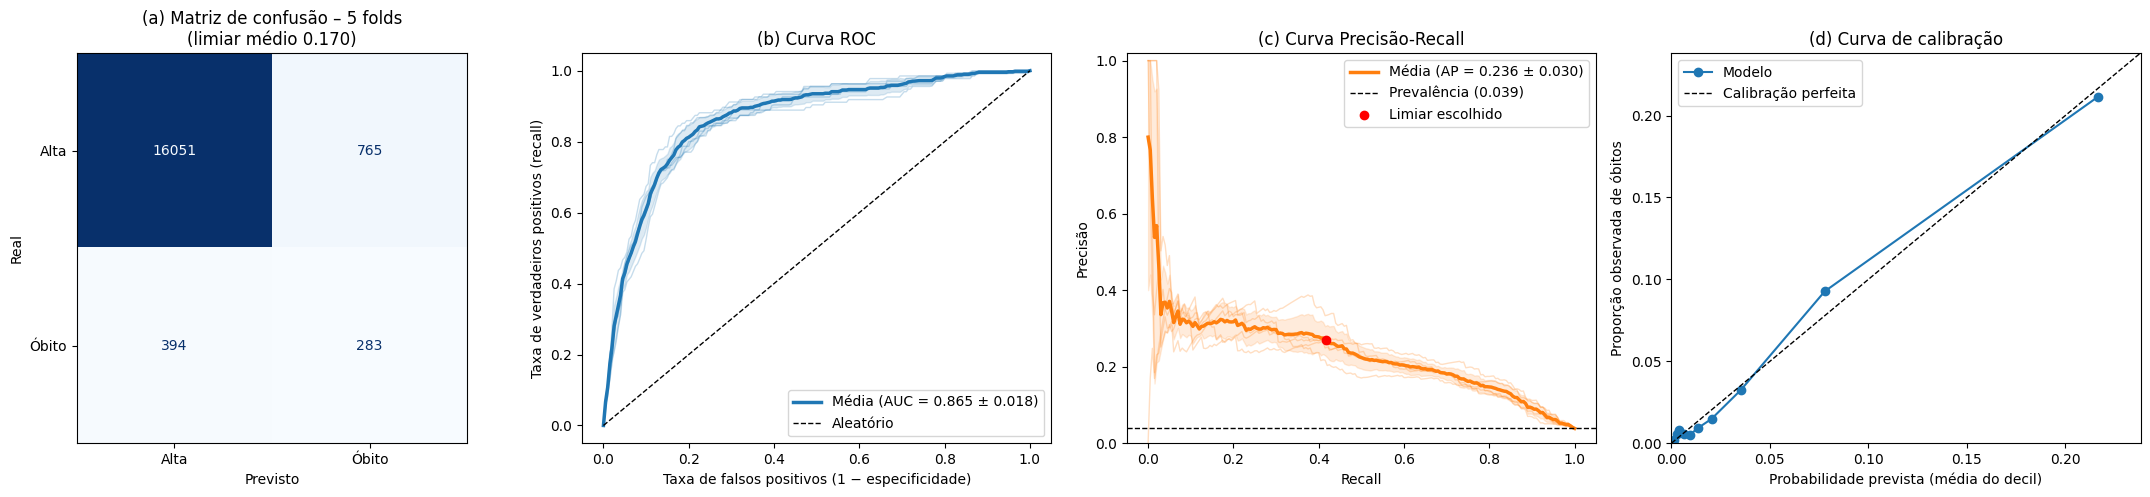

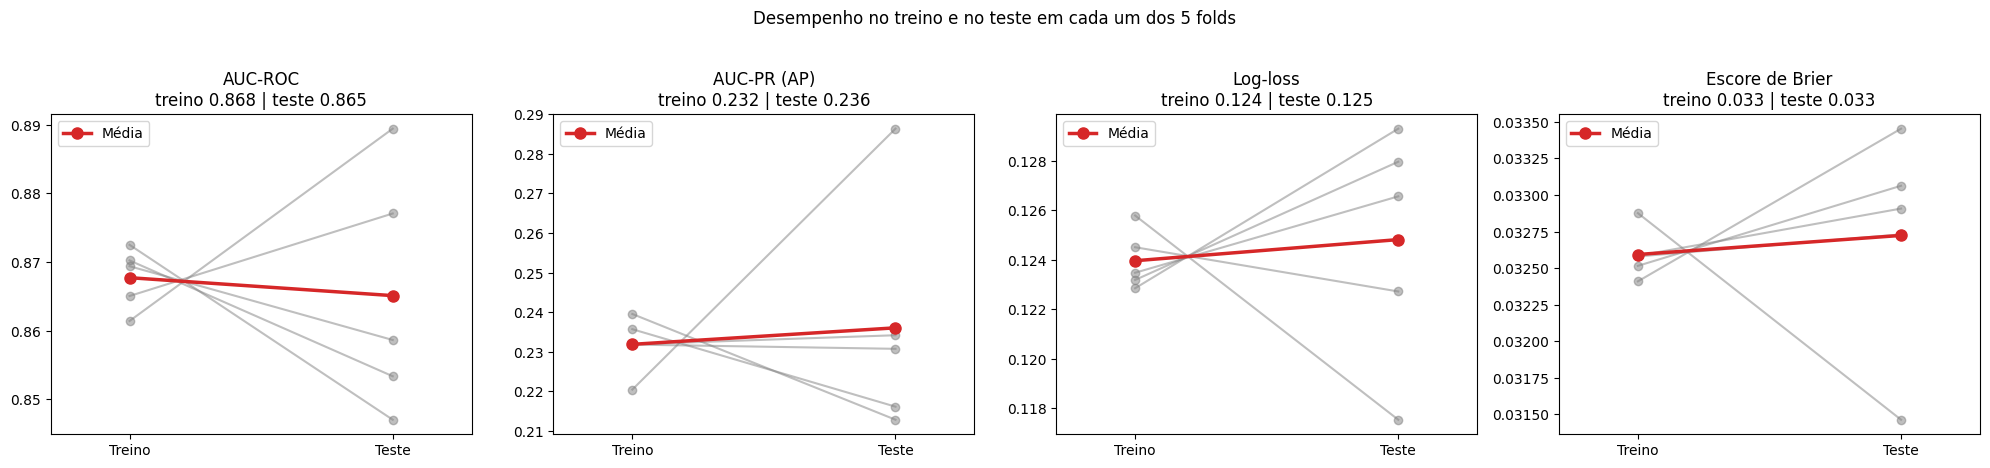


Imagens salvas: avaliacao_kfold.png e vies_variancia_kfold.png


In [35]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import StratifiedKFold
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, roc_curve, average_precision_score,
                             precision_recall_curve, log_loss, brier_score_loss,
                             precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

K = 5
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=42)
y_arr = y.to_numpy()
X_dados = df_final[features].apply(pd.to_numeric, errors="coerce")

prob_oof = np.zeros(len(y))
pred_oof = np.zeros(len(y), int)
grade = np.linspace(0, 1, 201)
tprs, precs, linhas, limiares = [], [], [], []


for k, (tr, te) in enumerate(skf.split(X_dados, y), start=1):
    X_tr, X_te, y_tr, y_te = X_dados.iloc[tr], X_dados.iloc[te], y_arr[tr], y_arr[te]

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        g = sm.GLM(y_tr, sm.add_constant(X_tr), family=sm.families.Binomial()).fit()
    p_tr = g.predict(sm.add_constant(X_tr, has_constant="add")).to_numpy()
    p_te = g.predict(sm.add_constant(X_te, has_constant="add")).to_numpy()

    pr, rc, th = precision_recall_curve(y_tr, p_tr)
    f1 = 2 * pr[:-1] * rc[:-1] / (pr[:-1] + rc[:-1] + 1e-12)
    lim = th[np.argmax(f1)]
    limiares.append(lim)

    prob_oof[te] = p_te
    pred_oof[te] = (p_te >= lim).astype(int)

    # Curvas do fold, interpoladas numa grade comum
    fpr, tpr, _ = roc_curve(y_te, p_te)
    tprs.append(np.interp(grade, fpr, tpr)); tprs[-1][0] = 0
    pr_te, rc_te, _ = precision_recall_curve(y_te, p_te)
    precs.append(np.interp(grade, rc_te[::-1], pr_te[::-1]))

    pc = pred_oof[te]
    linhas.append({"fold": k, "limiar": lim,
                   "AUC treino": roc_auc_score(y_tr, p_tr), "AUC teste": roc_auc_score(y_te, p_te),
                   "AP treino": average_precision_score(y_tr, p_tr), "AP teste": average_precision_score(y_te, p_te),
                   "LogLoss treino": log_loss(y_tr, p_tr), "LogLoss teste": log_loss(y_te, p_te),
                   "Brier treino": brier_score_loss(y_tr, p_tr), "Brier teste": brier_score_loss(y_te, p_te),
                   "Precisão": precision_score(y_te, pc, zero_division=0),
                   "Recall": recall_score(y_te, pc, zero_division=0),
                   "F1": f1_score(y_te, pc, zero_division=0)})

tab = pd.DataFrame(linhas).set_index("fold")
print("--- Métricas por fold ---")
print(tab.round(4).to_string())
print("\n--- Média e desvio-padrão ---")
print(tab.agg(["mean", "std"]).round(4).T.to_string())

auc_m, ap_m = tab["AUC teste"].mean(), tab["AP teste"].mean()
prev = y_arr.mean()


fig, ax = plt.subplots(1, 4, figsize=(22, 5))


ConfusionMatrixDisplay(confusion_matrix(y_arr, pred_oof, labels=[0, 1]),
                       display_labels=["Alta", "Óbito"]).plot(ax=ax[0], colorbar=False, cmap="Blues")
ax[0].set_title(f"(a) Matriz de confusão – {K} folds\n(limiar médio {np.mean(limiares):.3f})")
ax[0].set(xlabel="Previsto", ylabel="Real")


for t in tprs:
    ax[1].plot(grade, t, color="tab:blue", alpha=0.25, lw=1)
mt, st = np.mean(tprs, axis=0), np.std(tprs, axis=0)
ax[1].plot(grade, mt, color="tab:blue", lw=2.5,
           label=f"Média (AUC = {auc_m:.3f} ± {tab['AUC teste'].std():.3f})")
ax[1].fill_between(grade, np.clip(mt - st, 0, 1), np.clip(mt + st, 0, 1), color="tab:blue", alpha=0.15)
ax[1].plot([0, 1], [0, 1], "k--", lw=1, label="Aleatório")
ax[1].set(xlabel="Taxa de falsos positivos (1 − especificidade)",
          ylabel="Taxa de verdadeiros positivos (recall)", title="(b) Curva ROC")
ax[1].legend(loc="lower right")


for p in precs:
    ax[2].plot(grade, p, color="tab:orange", alpha=0.25, lw=1)
mp, sp = np.mean(precs, axis=0), np.std(precs, axis=0)
ax[2].plot(grade, mp, color="tab:orange", lw=2.5,
           label=f"Média (AP = {ap_m:.3f} ± {tab['AP teste'].std():.3f})")
ax[2].fill_between(grade, np.clip(mp - sp, 0, 1), np.clip(mp + sp, 0, 1), color="tab:orange", alpha=0.15)
ax[2].axhline(prev, color="k", ls="--", lw=1, label=f"Prevalência ({prev:.3f})")
ax[2].scatter(recall_score(y_arr, pred_oof), precision_score(y_arr, pred_oof),
              c="red", zorder=5, label="Limiar escolhido")
ax[2].set(xlabel="Recall", ylabel="Precisão", title="(c) Curva Precisão-Recall", ylim=(0, 1.02))
ax[2].legend()


frac, media = calibration_curve(y_arr, prob_oof, n_bins=10, strategy="quantile")
m = max(frac.max(), media.max()) * 1.1
ax[3].plot(media, frac, "o-", label="Modelo")
ax[3].plot([0, m], [0, m], "k--", lw=1, label="Calibração perfeita")
ax[3].set(xlim=(0, m), ylim=(0, m), xlabel="Probabilidade prevista (média do decil)",
          ylabel="Proporção observada de óbitos", title="(d) Curva de calibração")
ax[3].legend()

plt.tight_layout()
fig.savefig("avaliacao_kfold.png", dpi=200, bbox_inches="tight")
plt.show()


metricas = [("AUC", "AUC-ROC"), ("AP", "AUC-PR (AP)"), ("LogLoss", "Log-loss"), ("Brier", "Escore de Brier")]
fig, ax = plt.subplots(1, 4, figsize=(20, 4.5))
for a, (m_, nome) in zip(ax, metricas):
    tr_, te_ = tab[f"{m_} treino"], tab[f"{m_} teste"]
    for f in tab.index:
        a.plot([0, 1], [tr_[f], te_[f]], "-o", color="gray", alpha=0.5)
    a.plot([0, 1], [tr_.mean(), te_.mean()], "-o", color="tab:red", lw=2.5, ms=8, label="Média")
    a.set_xticks([0, 1], ["Treino", "Teste"]); a.set_xlim(-0.3, 1.3)
    a.set_title(f"{nome}\ntreino {tr_.mean():.3f} | teste {te_.mean():.3f}")
    a.legend()
fig.suptitle(f"Desempenho no treino e no teste em cada um dos {K} folds", y=1.03)
plt.tight_layout()
fig.savefig("vies_variancia_kfold.png", dpi=200, bbox_inches="tight")
plt.show()

print("\nImagens salvas: avaliacao_kfold.png e vies_variancia_kfold.png")

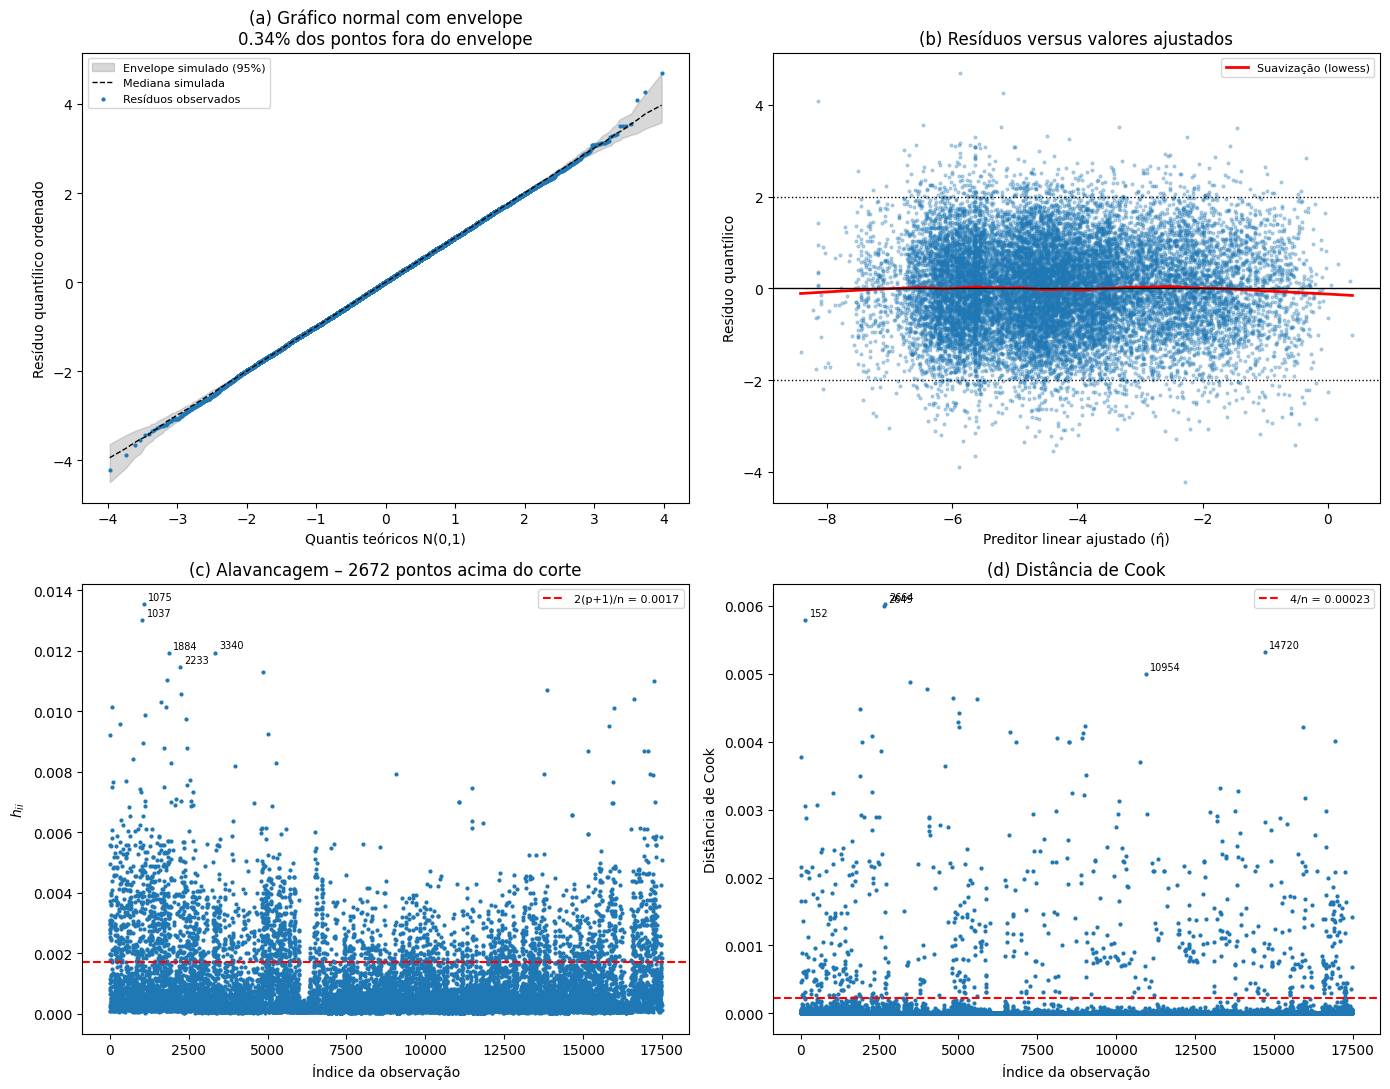

--- 5 observações mais influentes ---
          h_ii     Cook  resíduo quantílico  MORTE  prob. ajustada
2664   0.00204  0.00603             2.28096      1         0.02218
2649   0.00288  0.00599             2.59057      1         0.03118
152    0.00282  0.00579             1.92370      1         0.03163
14720  0.00012  0.00532             3.55634      1         0.00154
10954  0.00002  0.00500             4.08213      1         0.00029

Características dessas observações:
       IDADE  urgencia  cirurgico  alta_complex  gestao_estadual  cid_circulatorio  cid_digestivo  cid_endocrinas  cid_geniturinario  cid_lesoes_causas_externas  cid_neoplasias  cid_outros  cid_respiratorio  raca_negra
2664      76       0.0        1.0           0.0              0.0               0.0            0.0             1.0                0.0                         0.0             0.0         0.0               0.0         1.0
2649      85       0.0        1.0           0.0              0.0               0.0   

In [36]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import norm, chi2

rng = np.random.default_rng(42)


Xc = sm.add_constant(X)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    glm_full = sm.GLM(y, Xc, family=sm.families.Binomial()).fit()

y_v   = y.to_numpy()
p_hat = glm_full.fittedvalues.to_numpy()
eta   = Xc.to_numpy() @ glm_full.params.to_numpy()
n, k  = Xc.shape

def resid_quantilico(yv, p, rng):
    """Resíduo quantílico aleatorizado (Dunn & Smyth, 1996) para resposta Bernoulli."""
    a = np.where(yv == 1, 1 - p, 0.0)
    b = np.where(yv == 1, 1.0, 1 - p)
    u = np.clip(rng.uniform(a, b), 1e-12, 1 - 1e-12)
    return norm.ppf(u)

r_q = resid_quantilico(y_v, p_hat, rng)


B = 99
sims = np.empty((B, n))
for b in range(B):
    y_sim = rng.binomial(1, p_hat)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        g = sm.GLM(y_sim, Xc, family=sm.families.Binomial()).fit()
    sims[b] = np.sort(resid_quantilico(y_sim, g.fittedvalues.to_numpy(), rng))

env_inf, env_med, env_sup = np.percentile(sims, [2.5, 50, 97.5], axis=0)
teor = norm.ppf((np.arange(1, n + 1) - 0.375) / (n + 0.25))
r_ord = np.sort(r_q)
fora = np.mean((r_ord < env_inf) | (r_ord > env_sup))

infl = glm_full.get_influence()
h    = infl.hat_matrix_diag
cook = infl.cooks_distance[0]
corte_h    = 2 * k / n
corte_cook = 4 / n
idx = np.arange(n)


fig, ax = plt.subplots(2, 2, figsize=(14, 11))


a = ax[0, 0]
a.fill_between(teor, env_inf, env_sup, color="gray", alpha=0.3, label="Envelope simulado (95%)")
a.plot(teor, env_med, "k--", lw=1, label="Mediana simulada")
a.scatter(teor, r_ord, s=4, color="tab:blue", label="Resíduos observados")
a.set(xlabel="Quantis teóricos N(0,1)", ylabel="Resíduo quantílico ordenado",
      title=f"(a) Gráfico normal com envelope\n{100 * fora:.2f}% dos pontos fora do envelope")
a.legend(fontsize=8)


a = ax[0, 1]
a.scatter(eta, r_q, s=4, alpha=0.3, color="tab:blue")
suav = sm.nonparametric.lowess(r_q, eta, frac=0.2, it=0)
a.plot(suav[:, 0], suav[:, 1], color="red", lw=2, label="Suavização (lowess)")
a.axhline(0, color="k", lw=1)
for v in (-2, 2):
    a.axhline(v, color="k", ls=":", lw=1)
a.set(xlabel="Preditor linear ajustado (η̂)", ylabel="Resíduo quantílico",
      title="(b) Resíduos versus valores ajustados")
a.legend(fontsize=8)


a = ax[1, 0]
a.scatter(idx, h, s=4, color="tab:blue")
a.axhline(corte_h, color="red", ls="--", label=f"2(p+1)/n = {corte_h:.4f}")
for i in np.argsort(h)[-5:]:
    a.annotate(str(X.index[i]), (i, h[i]), fontsize=7, xytext=(3, 3), textcoords="offset points")
a.set(xlabel="Índice da observação", ylabel="$h_{ii}$",
      title=f"(c) Alavancagem – {np.sum(h > corte_h)} pontos acima do corte")
a.legend(fontsize=8)

# (d) Distância de Cook
a = ax[1, 1]
a.scatter(idx, cook, s=4, color="tab:blue")
a.axhline(corte_cook, color="red", ls="--", label=f"4/n = {corte_cook:.5f}")
for i in np.argsort(cook)[-5:]:
    a.annotate(str(X.index[i]), (i, cook[i]), fontsize=7, xytext=(3, 3), textcoords="offset points")
a.set(xlabel="Índice da observação", ylabel="Distância de Cook",
      title="(d) Distância de Cook")
a.legend(fontsize=8)

plt.tight_layout()
fig.savefig("diagnostico.png", dpi=200, bbox_inches="tight")
plt.show()


top = np.argsort(cook)[-5:][::-1]
tab_infl = pd.DataFrame({"h_ii": h[top], "Cook": cook[top], "resíduo quantílico": r_q[top],
                         "MORTE": y_v[top], "prob. ajustada": p_hat[top]},
                        index=X.index[top])
print("--- 5 observações mais influentes ---")
print(tab_infl.round(5).to_string())
print("\nCaracterísticas dessas observações:")
print(X.loc[X.index[top]].to_string())

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    g_sem = sm.GLM(y.drop(X.index[top]), Xc.drop(X.index[top]),
                   family=sm.families.Binomial()).fit()
var = pd.DataFrame({"completo": glm_full.params, "sem as 5": g_sem.params,
                    "variação %": 100 * (g_sem.params - glm_full.params) / glm_full.params.abs()})
print("\n--- Coeficientes com e sem as 5 observações mais influentes ---")
print(var.round(4).to_string())
print(f"\nMaior variação absoluta: {var['variação %'].abs().max():.1f}%")

grupos = pd.qcut(p_hat, 10, duplicates="drop")
hl = pd.DataFrame({"y": y_v, "p": p_hat, "g": grupos}).groupby("g", observed=True).agg(
    n=("y", "size"), obs=("y", "sum"), esp=("p", "sum"))
HL = (((hl["obs"] - hl["esp"]) ** 2) / (hl["esp"] * (1 - hl["esp"] / hl["n"]))).sum()
gl = len(hl) - 2
print("\n--- Teste de Hosmer-Lemeshow ---")
print(hl.assign(esp=hl["esp"].round(1)).to_string())
print(f"\nHL = {HL:.2f} | g.l. = {gl} | p-valor = {chi2.sf(HL, gl):.4f}")